![Crowded city](city-1265055_1280.jpg)

In the quest for efficiency and effectiveness in urban transportation, finding the optimal routes to take passengers from their initial locations to their desired destinations is paramount. This challenge is not just about reducing travel time; it's about enhancing the overall experience for both drivers and passengers, ensuring safety, and minimizing environmental impact. 

You have been asked to revolutionize the way taxis navigate the urban landscape, ensuring passengers reach their destinations swiftly, safely, and satisfactorily. As an initial step, your goal is to build a reinforcement learning agent that solves this problem within a simulated environment.

## The Taxi-v3 environment
The Taxi-v3 environment is a strategic simulation, offering a grid-based arena where a taxi navigates to address daily challenges akin to those faced by a taxi driver. This environment is defined by a 5x5 grid where the taxi's mission involves picking up a passenger from one of four specific locations (marked as Red, Green, Yellow, and Blue) and dropping them off at another designated spot. The goal is to accomplish this with minimal time on the road to maximize rewards, emphasizing the need for route optimization and efficient decision-making for passenger pickup and dropoff.

### Key Components:
- **Action Space:** Comprises six actions where 0 moves the taxi south, 1 north, 2 east, 3 west, 4 picks up a passenger, and 5 drops off a passenger.
- **Observation Space:** Comprises 500 discrete states, accounting for 25 taxi positions, 5 potential passenger locations, and 4 destinations. 
- **Rewards System:** Includes a penalty of -1 for each step taken without other rewards, +20 for successful passenger delivery, and -10 for illegal pickup or dropoff actions. Actions resulting in no operation, like hitting a wall, also incur a time step penalty.

![Taxi-v3 environment snapshot](Taxi_snap.png)


In [16]:
! pip install gymnasium imageio
! pip install gymnasium[toy-text]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 1.2 MB/s eta 0:00:0000:0100:01m


In [7]:
# Import Libraries
import numpy as np
import gymnasium as gym
import imageio
from IPython.display import Image
from gymnasium.utils import seeding

# Initialize the Taxi-v3 environment
env = gym.make("Taxi-v4", render_mode='rgb_array')

# Seed the environment for reproducibility
env.np_random, _ = seeding.np_random(42)
env.action_space.seed(42)
np.random.seed(42)

# Maximum number of actions per training episode
max_actions = 100 
num_episodes = 2000

In [8]:
# Initialize Variables 
q_table = np.zeros((env.observation_space.n,env.action_space.n))
episode_returns = []
alpha = 0.1       # Learning rate
gamma = 0.99      # Discount factor
epsilon = 0.1     # Exploration probability

In [9]:
def epsilon_greedy(state,epsilon):
    if np.random.rand() < epsilon:
        return env.action_space.sample()
    else:
        return np.argmax(q_table[state])        

In [10]:
def update_q_table(state, action, reward, next_state):
    q_table[state, action] = q_table[state, action] + alpha * (
        reward + gamma * np.max(q_table[next_state, :]) - q_table[state, action]
    )

In [11]:
for episode in range(num_episodes):
    state, info = env.reset(seed=42)
    total_reward = 0

    for action in range(max_actions):
        action = epsilon_greedy(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)

        update_q_table(state, action, reward, next_state)
        
        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    episode_returns.append(total_reward)   
        
print("Total Episodes Trained: ", len(episode_returns))

Total Episodes Trained:  2000


In [12]:
# Show Learned Policy from Q-Table
policy = {state: np.argmax(q_table[state, :]) for state in range(env.observation_space.n)}

print("Learned Q-table:\n", q_table)
print("Derived policy:", policy)

Learned Q-table:
 [[ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [-0.36271    -0.370729   -0.37162    -0.2997001  -0.35493922 -1.        ]
 ...
 [ 0.          0.          0.          0.          0.          0.        ]
 [-2.0791324  -2.189284   -2.07403953 -2.12131532 -2.997001   -2.92774064]
 [ 0.          0.          0.          0.          0.          0.        ]]
Derived policy: {0: np.int64(0), 1: np.int64(0), 2: np.int64(3), 3: np.int64(0), 4: np.int64(0), 5: np.int64(0), 6: np.int64(2), 7: np.int64(0), 8: np.int64(0), 9: np.int64(0), 10: np.int64(0), 11: np.int64(0), 12: np.int64(0), 13: np.int64(0), 14: np.int64(1), 15: np.int64(0), 16: np.int64(0), 17: np.int64(0), 18: np.int64(0), 19: np.int64(0), 20: np.int64(0), 21: np.int64(0), 22: np.int64(2), 23: np.int64(0), 24: np.int64(0), 25: np.int64(0), 26: np.int64(0), 27: np.int64(0), 28: np.int64(0), 29: np.int64(0), 30: np.in

In [17]:
state, _ = env.reset(seed=42)
frames = []
episode_total_reward = 0
max_test_actions = 16

for step in range(max_test_actions):
    frames.append(env.render())    
    action = policy[state]
    
    next_state, reward, terminated, truncated, _ = env.step(action)
    
    total_reward += reward
    
    state = next_state
    
    if terminated or truncated:
        frames.append(env.render()) 
        break

env.close()

print("Total reward in test episode:", total_reward)
print("Number of frames collected:", len(frames))

Total reward in test episode: 4
Number of frames collected: 14


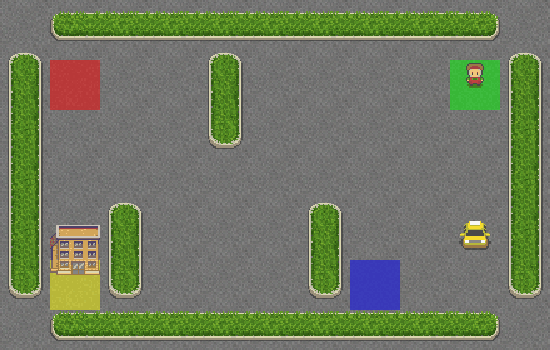

In [18]:
# Once you are done, run this cell to visualize the agent's behavior through the episode
# Save frames as a GIF
imageio.mimsave('taxi_agent_behavior.gif', frames, fps=5, loop=0)

# Display GIF
gif_path = "taxi_agent_behavior.gif" 
Image(gif_path) 